
# EMAT 32210: Analysis Report

**Author:** Bogdan Gura  
**Date:** November 11, 2026  
**Class:** EMAT 32210 Section 001

## Research Question

Do billionaires in the Technology industry have higher net worth than billionaires in other industries?

## Hypothesis

Billionaires classified in the Technology industry will have a higher average net worth than billionaires classified in other industries.

## Theoretical Application

This study explores the relationship between industry classification and individual wealth. The technology sector has produced several highly successful companies and entrepreneurs, making it interesting to investigate whether individuals associated with this industry have accumulated greater wealth compared to billionaires in other economic sectors.

The analysis also considers how the distribution of wealth varies across industries, particularly the influence of exceptionally high net-worth individuals on group averages.

## Statistical Application

Billionaires will be divided into two groups: Technology and Other Industries. Their estimated net worth will be compared using descriptive statistics and visualizations, including a histogram, scatter plot, and boxplot.

An Ordinary Least Squares (OLS) regression model will also be used to investigate whether the average net worth of Technology billionaires differs significantly from that of billionaires in other industries. The analysis will examine the estimated difference between group averages, regression coefficients, and p-values.

## Variables

- **Current net worth:** Estimated current wealth of an individual billionaire, measured in U.S. dollars.
- **Previous net worth:** Previously recorded estimated wealth, measured in U.S. dollars.
- **Industry classification:** The industry or industries associated with each billionaire.
- **Industry group:** A categorical variable identifying individuals as either Technology or Other Industries.
- **Age:** The billionaire's recorded age in years.
- **Rank:** The individual's position on the Forbes Billionaires List.


## Dataset Source

The dataset was obtained from a [developer-maintained GitHub repository](https://github.com/sharmadhiraj/free-json-datasets/blob/master/docs/economy-finance/forbes_billionaires_list.json).

It contains publicly available data based on the Forbes Billionaires List, including net worth, industry, age, and ranking.
Since Forbes does not provide a public API or official JSON download, I used this third-party dataset as an alternative.
I personally cross-checked its information against Forbes magazine publications to assess its accuracy and consistency.

## Academic Honesty & AI Disclosure Statement

As a student in EMAT 32210, I selected and examined the Forbes Billionaires List JSON dataset and developed the research question and hypothesis for this analysis. I used the dataset's existing numerical and categorical variables to investigate differences in net worth between Technology billionaires and billionaires in other industries.

I utilized AI tools exclusively to assist with creating and formatting the Matplotlib visualizations, as well as reorganizing the dataset by classifying billionaires into Technology and Other Industries categories. The data extraction, JSON loading, pandas DataFrame manipulation, statistical analysis, interpretation of results, and remaining portions of the project were completed by me.

I take full responsibility for reviewing, executing, and understanding the code and analysis presented in this notebook. I have disclosed this assistance in accordance with Kent State's EMAT 32210 academic honesty and AI usage expectations.


In [3]:
#Importing Modulues and summarizing imported data

import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from IPython.display import display

DATA_PATH = Path("../Raw Data/forbes_billionaires_list.json")

with DATA_PATH.open("r", encoding="utf-8") as file:
    raw_json = json.load(file)

if isinstance(raw_json, dict) and isinstance(raw_json.get("data"), list):
    records = raw_json["data"]
elif isinstance(raw_json, list):
    records = raw_json
else:
    raise ValueError("Expected a JSON list or a JSON object containing a list under the 'data' key.")

df = pd.DataFrame(records)

print(f"Number of observations loaded: {len(df):,}")
print("Top-level dataset title:", raw_json.get("title", "Not provided") if isinstance(raw_json, dict) else "Not provided")
print("Dataset update date:", raw_json.get("updated_at", "Not provided") if isinstance(raw_json, dict) else "Not provided")
display(df.head())

Number of observations loaded: 3,109
Top-level dataset title: Forbes Billionaires List
Dataset update date: August 20, 2025 09:42 AM UTC


,rank,name,last_name,source,industries,country,gender,age,current_worth,previous_worth,image_url
0,1,Elon Musk,Musk,"Tesla, SpaceX",[Automotive],United States,M,54,413046544000,416338889179,https://specials-images.forbesimg.com/imageser...
1,2,Larry Ellison,Ellison,Oracle,[Technology],United States,M,81,279881344000,295673532565,https://specials-images.forbesimg.com/imageser...
2,3,Mark Zuckerberg,Zuckerberg,Facebook,[Technology],United States,M,41,259176673000,264605418320,https://specials-images.forbesimg.com/imageser...
3,4,Jeff Bezos,Bezos,Amazon,[Technology],United States,M,61,239990255000,243065809282,https://specials-images.forbesimg.com/imageser...
4,5,Larry Page,Page,Google,[Technology],United States,M,52,169543401000,171000557476,https://specials-images.forbesimg.com/imageser...


In [4]:
"""
This code copies the original dataset and checks that required columns exist.
It standardizes industry labels and converts relevant numerical columns into numeric values.
Billionaires are classified into Technology or Other Industries based on their industry labels.
Net worth is converted from U.S. dollars into billions for easier comparison.
Finally, it removes invalid records and displays the excluded rows, group counts, and prepared data.
"""

analysis_df = df.copy()

required_columns = ["current_worth", "industries"]
missing_columns = [column for column in required_columns if column not in analysis_df.columns]
if missing_columns:
    raise KeyError(f"The JSON file is missing required column(s): {missing_columns}")

def normalize_industries(value):
    if isinstance(value, list):
        return [str(item).strip() for item in value if pd.notna(item) and str(item).strip()]
    if isinstance(value, str) and value.strip():
        return [value.strip()]
    return []

analysis_df["industries_list"] = analysis_df["industries"].apply(normalize_industries)
analysis_df["current_worth"] = pd.to_numeric(analysis_df["current_worth"], errors="coerce")

if "previous_worth" in analysis_df.columns:
    analysis_df["previous_worth"] = pd.to_numeric(analysis_df["previous_worth"], errors="coerce")
if "age" in analysis_df.columns:
    analysis_df["age"] = pd.to_numeric(analysis_df["age"], errors="coerce")
if "rank" in analysis_df.columns:
    analysis_df["rank"] = pd.to_numeric(analysis_df["rank"], errors="coerce")

analysis_df["industry_group"] = analysis_df["industries_list"].apply(
    lambda labels: "Technology" if "Technology" in labels else "Other industries"
)
analysis_df["current_worth_billions"] = analysis_df["current_worth"] / 1_000_000_000

before_cleaning = len(analysis_df)
analysis_df = analysis_df.dropna(subset=["current_worth", "industry_group"]).copy()
analysis_df = analysis_df[analysis_df["current_worth"] > 0].copy()
removed_rows = before_cleaning - len(analysis_df)

print(f"Rows excluded because net worth was missing, invalid, or non-positive: {removed_rows}")
print(f"Rows available for analysis: {len(analysis_df):,}")
print("\nGroup counts:")
display(analysis_df["industry_group"].value_counts().to_frame("number_of_billionaires"))
print("\nPrepared data:")
display(analysis_df[["name", "industries_list", "industry_group", "current_worth_billions"]].head())

Rows excluded because net worth was missing, invalid, or non-positive: 4
Rows available for analysis: 3,105

Group counts:


,number_of_billionaires
industry_group,
Other industries,2690
Technology,415



Prepared data:


,name,industries_list,industry_group,current_worth_billions
0,Elon Musk,[Automotive],Other industries,413.046544
1,Larry Ellison,[Technology],Technology,279.881344
2,Mark Zuckerberg,[Technology],Technology,259.176673
3,Jeff Bezos,[Technology],Technology,239.990255
4,Larry Page,[Technology],Technology,169.543401


In [5]:
"""
Snippet Calculates descriptive statistics for both industry groups,
including the number of observations, mean, median, standard deviation,
minimum, and maximum net worth values. It then displays the summary
and compares the average and median wealth of Technology billionaires
against billionaires in Other Industries, checking that both groups exist.
"""

group_summary = analysis_df.groupby("industry_group")["current_worth_billions"].agg(
    count="count",
    mean="mean",
    median="median",
    standard_deviation="std",
    minimum="min",
    maximum="max"
).round(2)

display(group_summary)

if set(["Technology", "Other industries"]).issubset(group_summary.index):
    tech_mean = group_summary.loc["Technology", "mean"]
    other_mean = group_summary.loc["Other industries", "mean"]
    tech_median = group_summary.loc["Technology", "median"]
    other_median = group_summary.loc["Other industries", "median"]
    print(f"Mean net worth — Technology: ${tech_mean:,.2f} billion")
    print(f"Mean net worth — Other industries: ${other_mean:,.2f} billion")
    print(f"Median net worth — Technology: ${tech_median:,.2f} billion")
    print(f"Median net worth — Other industries: ${other_median:,.2f} billion")
else:
    print("Warning: Both groups are not represented. Check the industry labels and classification rule.")

,count,mean,median,standard_deviation,minimum,maximum
industry_group,,,,,,
Other industries,2690,5.12,2.53,12.32,0.4,413.05
Technology,415,9.04,2.44,28.44,1.0,279.88


Mean net worth — Technology: $9.04 billion
Mean net worth — Other industries: $5.12 billion
Median net worth — Technology: $2.44 billion
Median net worth — Other industries: $2.53 billion


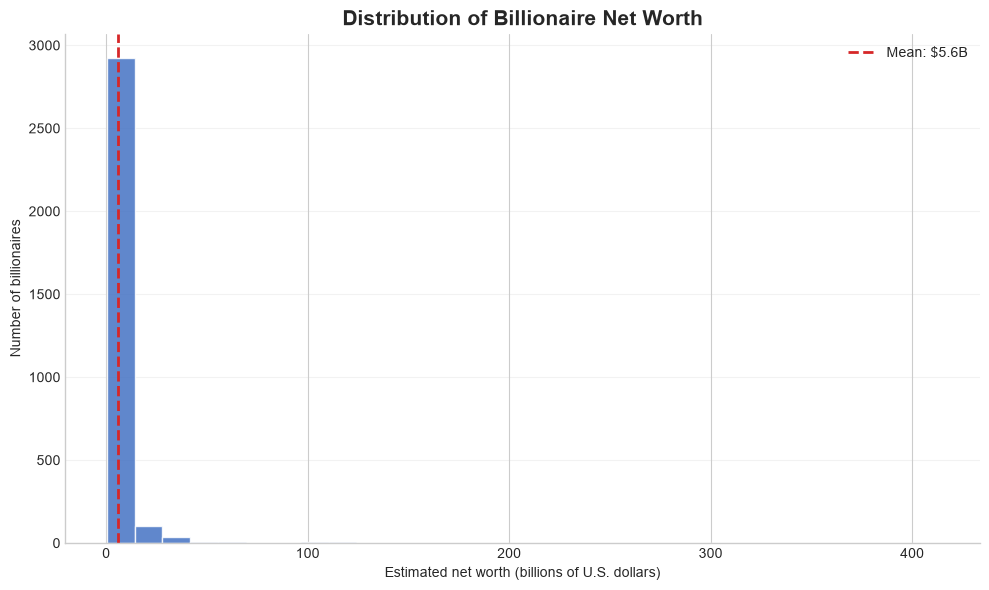

The median net worth is $2.50 billion.
The mean net worth is $5.64 billion.
The maximum net worth is $413.05 billion.


In [6]:
"""
Creates a histogram showing the distribution of billionaire net worth,
using 30 bins to group individuals by their estimated wealth.
A vertical dashed line highlights the overall mean net worth.
The chart includes labels, a title, gridlines, and styling to improve readability.
Finally, it prints the median, mean, and maximum net worth for comparison.
"""

plt.style.use("seaborn-v0_8-whitegrid")

values = analysis_df["current_worth_billions"].dropna()
overall_mean = values.mean()

fig, ax = plt.subplots(figsize=(10, 6))
ax.hist(values, bins=30, color="#4472C4", edgecolor="white", alpha=0.85)
ax.axvline(overall_mean, color="#D62728", linestyle="--", linewidth=2,
           label=f"Mean: ${overall_mean:,.1f}B")
ax.set_title("Distribution of Billionaire Net Worth", fontsize=15, weight="bold")
ax.set_xlabel("Estimated net worth (billions of U.S. dollars)")
ax.set_ylabel("Number of billionaires")
ax.legend()
ax.grid(axis="y", alpha=0.25)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
fig.tight_layout()
plt.show()

print(f"The median net worth is ${values.median():,.2f} billion.")
print(f"The mean net worth is ${overall_mean:,.2f} billion.")
print(f"The maximum net worth is ${values.max():,.2f} billion.")

### Histogram Analysis
The histogram reveals a heavily right-skewed distribution of billionaire wealth.
Most individuals cluster toward the lower end of the distribution.
A few exceptionally wealthy individuals pull the overall mean upward.

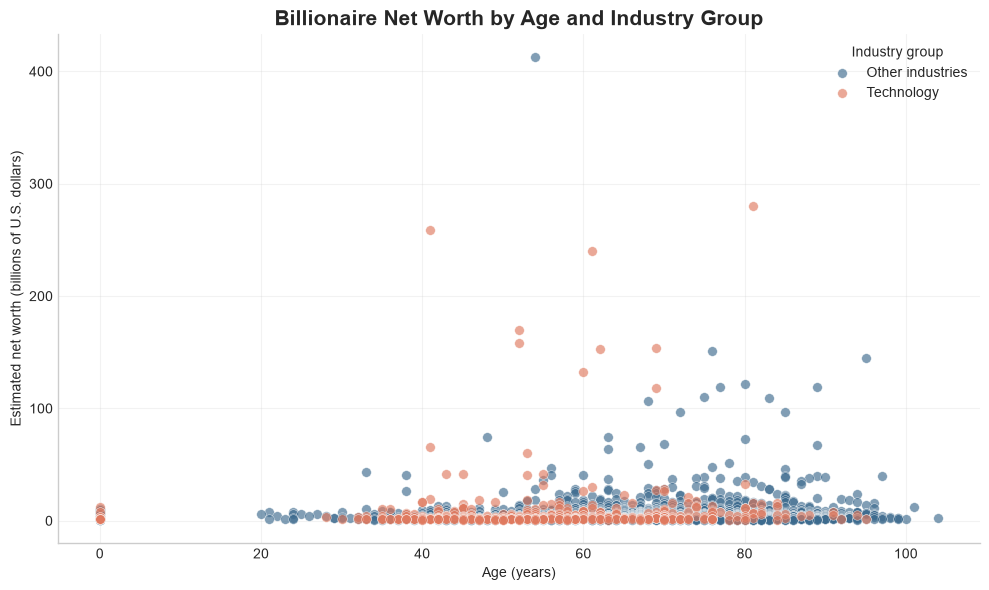

Number of records in scatter plot: 3,105
Pearson correlation between age and net worth: 0.046


In [7]:
"""
This code creates a scatter plot comparing billionaire age and net worth,
with separate colors representing Technology and Other Industries.
It excludes records with missing age or net worth values before plotting.
The chart includes labels, a legend, gridlines, and formatting to improve readability.
Finally, it displays the number of records analyzed and calculates the Pearson correlation
to measure the relationship between age and net worth.
"""

if "age" not in analysis_df.columns:
    print("The dataset does not contain an age column, so the scatter plot cannot be created.")
else:
    scatter_df = analysis_df.dropna(subset=["age", "current_worth_billions"]).copy()
    fig, ax = plt.subplots(figsize=(10, 6))
    colors = {"Technology": "#E07A5F", "Other industries": "#3D6B8E"}

    for group, group_data in scatter_df.groupby("industry_group"):
        ax.scatter(
            group_data["age"],
            group_data["current_worth_billions"],
            label=group,
            color=colors.get(group, "#777777"),
            alpha=0.65,
            s=48,
            edgecolors="white",
            linewidths=0.4
        )

    ax.set_title("Billionaire Net Worth by Age and Industry Group", fontsize=15, weight="bold")
    ax.set_xlabel("Age (years)")
    ax.set_ylabel("Estimated net worth (billions of U.S. dollars)")
    ax.legend(title="Industry group")
    ax.grid(True, alpha=0.25)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    fig.tight_layout()
    plt.show()

    print(f"Number of records in scatter plot: {len(scatter_df):,}")
    print("Pearson correlation between age and net worth:",
          round(scatter_df["age"].corr(scatter_df["current_worth_billions"]), 3))

### Scatter Plot Analysis
The scatter plot shows a negligible Pearson correlation between age and net worth.
This suggests little linear relationship between the two variables.
It also highlights that some of the highest net-worth outliers belong to the Technology sector.

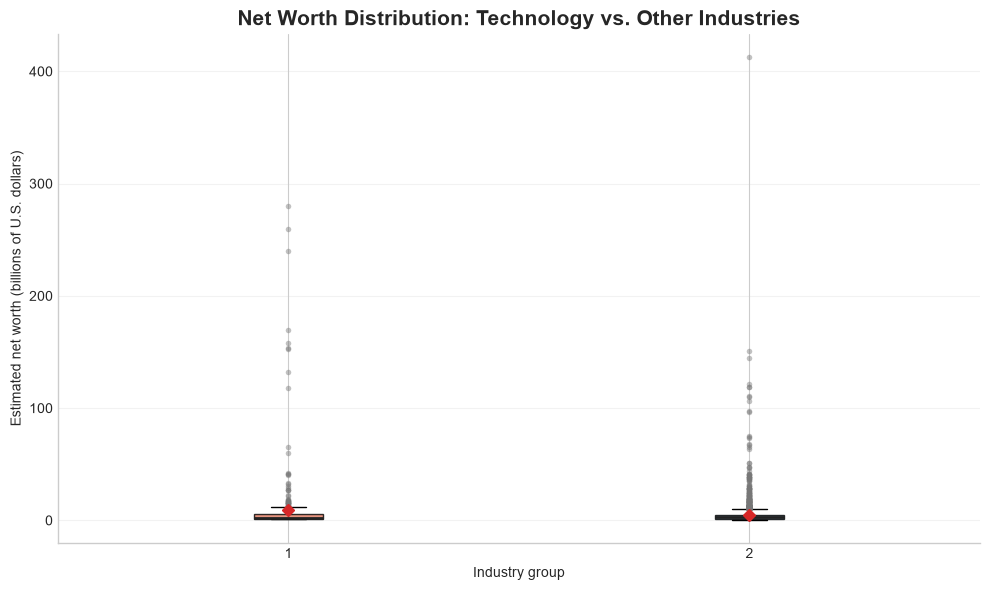

Technology: median = $2.44B; n = 415
Other industries: median = $2.53B; n = 2690


In [8]:
"""
This code creates a boxplot comparing net worth distributions across both industry groups.
It displays the median, mean, and potential outliers for each group.
Different colors and marker styles help distinguish the two categories.
The chart includes descriptive labels, gridlines, and formatting for readability.
Finally, it prints each group's median net worth and number of observations.
"""

group_order = ["Technology", "Other industries"]
box_data = [
    analysis_df.loc[analysis_df["industry_group"] == group, "current_worth_billions"].dropna().values
    for group in group_order
]

fig, ax = plt.subplots(figsize=(10, 6))
box = ax.boxplot(
    box_data,
    label=group_order,
    patch_artist=True,
    showmeans=True,
    meanprops={"marker": "D", "markerfacecolor": "#D62728",
               "markeredgecolor": "#D62728", "markersize": 6},
    medianprops={"color": "#222222", "linewidth": 2},
    flierprops={"marker": "o", "markerfacecolor": "#777777",
                "markeredgecolor": "none", "alpha": 0.45, "markersize": 4}
)

for patch, color in zip(box["boxes"], ["#E07A5F", "#3D6B8E"]):
    patch.set_facecolor(color)
    patch.set_alpha(0.8)

ax.set_title("Net Worth Distribution: Technology vs. Other Industries", fontsize=15, weight="bold")
ax.set_xlabel("Industry group")
ax.set_ylabel("Estimated net worth (billions of U.S. dollars)")
ax.grid(axis="y", alpha=0.25)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
fig.tight_layout()
plt.show()

for group, data in zip(group_order, box_data):
    if len(data):
        print(f"{group}: median = ${np.median(data):,.2f}B; n = {len(data)}")

### Boxplot Analysis
The boxplot shows that both groups have nearly identical median net worth, at approximately $2.5 billion.
However, Technology billionaires have more extreme upper outliers, which substantially increase their group's average net worth.

In [9]:
# Fit an Ordinary Least Squares model comparing net worth between Technology and Other Industries
ols_model = smf.ols("current_worth_billions ~ C(industry_group, Treatment(reference='Other industries'))", data=analysis_df).fit()
print(ols_model.summary())

                              OLS Regression Results                              
Dep. Variable:     current_worth_billions   R-squared:                       0.007
Model:                                OLS   Adj. R-squared:                  0.007
Method:                     Least Squares   F-statistic:                     23.16
Date:                    Wed, 11 Nov 2026   Prob (F-statistic):           1.56e-06
Time:                            12:19:54   Log-Likelihood:                -12910.
No. Observations:                    3105   AIC:                         2.582e+04
Df Residuals:                        3103   BIC:                         2.584e+04
Df Model:                               1                                         
Covariance Type:                nonrobust                                         
                                                                               coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------

## Conclusion
### Hypothesis Testing
The results support the hypothesis that billionaires in the Technology sector have a higher average net worth than those in other industries.
The average net worth of Technology billionaires is 9.04 billion USD, compared to 5.12 billion USD for billionaires in other sectors.
### Summary of Findings
Despite the difference in averages, the median net worth is nearly identical between the groups.
Technology billionaires have a median net worth of 2.44 billion USD, compared to 2.53 billion USD in other industries.
This suggests that a small number of exceptionally wealthy individuals significantly increase the Technology group's average.
### Final Interpretation
The Technology sector produces some of the wealthiest individuals in the dataset.
However, the typical Technology billionaire does not necessarily have greater wealth than someone in another industry.
The OLS regression confirms that this 3.93 billion USD average wealth difference is statistically significant (p < 0.001).